# Exercise 2 · Streaming Pipeline — Real-time Clickstream Analysis

## The problem

Users browse a website. Every click is logged as an event: which page, which user, at what time. You need a **real-time pipeline** that continuously answers:

- How many page-views per page in the **last 2 minutes**?
- How many **unique active users** right now?
- Which pages are **trending** (velocity spike in the last window)?

## Pipeline
```
Kafka producer (Python thread)
         ↓ topic: clickstream
Spark Structured Streaming
         ↓  2-min sliding window + watermark
   console sink (debug)  +  PostgreSQL sink (live dashboard)
         ↓
   DuckDB ad-hoc queries on PostgreSQL
```

## Skills practiced
- `kafka-python` producer with background thread
- `readStream` + JSON schema
- `window()` + `watermark` for late-data handling
- `foreachBatch` sink → write each micro-batch to PostgreSQL
- Distinguishing `append`, `update`, and `complete` output modes
- DuckDB querying a live PostgreSQL table

---
## Step 0 · Setup

In [17]:
import os, json, time, random, threading
from datetime import datetime, timezone
from kafka import KafkaProducer
from pyspark.sql import SparkSession
from pyspark.sql import functions as F
from pyspark.sql.types import *

SPARK_MASTER  = os.getenv('SPARK_MASTER',            'spark://spark-master:7077')
KAFKA_SERVERS = os.getenv('KAFKA_BOOTSTRAP_SERVERS', 'kafka:29092')
PG_URL   = f"jdbc:postgresql://{os.getenv('POSTGRES_HOST','postgres')}:5432/{os.getenv('POSTGRES_DB','sandbox')}"
PG_PROPS = {'user': os.getenv('POSTGRES_USER','spark'),
            'password': os.getenv('POSTGRES_PASSWORD','spark123'),
            'driver': 'org.postgresql.Driver'}

spark = (
    SparkSession.builder
    .appName('clickstream-streaming')
    .master(SPARK_MASTER)
    .getOrCreate()
)
spark.sparkContext.setLogLevel('WARN')
print(f'Spark {spark.version}  master: {spark.sparkContext.master}')

Spark 4.0.3  master: spark://spark-master:7077


---
## Step 1 · Kafka producer — emit clickstream events

Each event is a JSON object:
```json
{"event_id": "uuid", "user_id": 42, "page": "/products", "referrer": "/home", "ts": "2026-06-17T20:00:00Z"}
```

We run it in a background thread so the notebook kernel stays free for the streaming query below.

In [18]:
import uuid

PAGES = [
    '/home', '/products', '/products/laptop', '/products/phone',
    '/cart', '/checkout', '/blog', '/about', '/search',
]
# Pages with higher weight → more traffic (hot pages)
PAGE_WEIGHTS = [10, 20, 15, 12, 8, 5, 6, 3, 10]
N_USERS = 200

producer = KafkaProducer(
    bootstrap_servers=KAFKA_SERVERS,
    value_serializer=lambda v: json.dumps(v).encode(),
)

_stop_producer = threading.Event()

def run_producer(events_per_second=5):
    count = 0
    delay = 1.0 / events_per_second
    while not _stop_producer.is_set():
        page = random.choices(PAGES, weights=PAGE_WEIGHTS)[0]
        event = {
            'event_id': str(uuid.uuid4()),
            'user_id':  random.randint(1, N_USERS),
            'page':     page,
            'referrer': random.choice(PAGES + [None]),
            'ts':       datetime.now(timezone.utc).isoformat(),
        }
        producer.send('clickstream', value=event)
        count += 1
        if count % 50 == 0:
            print(f'  Producer: {count} events sent')
        time.sleep(delay)
    producer.flush()
    print(f'Producer stopped. Total sent: {count}')

_stop_producer.clear()
t = threading.Thread(target=run_producer, args=(5,), daemon=True)
t.start()
print('Producer running at ~5 events/sec — check Kafka UI at http://localhost:8090')

Producer running at ~5 events/sec — check Kafka UI at http://localhost:8090


  Producer: 50 events sent


---
## Step 2 · Read the stream from Kafka

`startingOffsets='latest'` — we only care about events arriving from now on.
Use `'earliest'` if you want to replay everything already in the topic.

In [19]:
click_schema = StructType([
    StructField('event_id', StringType()),
    StructField('user_id',  IntegerType()),
    StructField('page',     StringType()),
    StructField('referrer', StringType()),
    StructField('ts',       StringType()),
])

raw = (
    spark.readStream
    .format('kafka')
    .option('kafka.bootstrap.servers', KAFKA_SERVERS)
    .option('subscribe', 'clickstream')
    .option('startingOffsets', 'latest')
    .load()
)

clicks = (
    raw
    .select(F.from_json(F.col('value').cast('string'), click_schema).alias('c'))
    .select('c.*')
    .withColumn('event_time', F.to_timestamp('ts'))
    .drop('ts')
)

clicks.printSchema()

root
 |-- event_id: string (nullable = true)
 |-- user_id: integer (nullable = true)
 |-- page: string (nullable = true)
 |-- referrer: string (nullable = true)
 |-- event_time: timestamp (nullable = true)



---
## Step 3 · Window aggregation

### Key concepts

| Concept | What it does |
|---|---|
| `window(col, '2 minutes', '30 seconds')` | Sliding window: 2-min wide, slides every 30 s |
| `.withWatermark('event_time', '15 seconds')` | Drop events arriving >15 s late |
| `outputMode('update')` | Emit rows as they change (good for dashboards) |
| `outputMode('append')` | Emit rows only once, after watermark passes |

For a live dashboard we want **update** — we re-emit each window row every trigger, showing current counts.

In [20]:
windowed = (
    clicks
    .withWatermark('event_time', '15 seconds')
    .groupBy(
        F.window('event_time', '2 minutes', '30 seconds'),
        'page',
    )
    .agg(
        F.count('*').alias('pageviews'),
        F.approx_count_distinct('user_id').alias('unique_users'),
    )
    .select(
        F.col('window.start').alias('window_start'),
        F.col('window.end').alias('window_end'),
        'page',
        'pageviews',
        'unique_users',
    )
)

  Producer: 100 events sent


---
## Step 4 · Write to sinks

### `foreachBatch` explained

Instead of a built-in sink, `foreachBatch` hands each micro-batch to a Python function as a **static** DataFrame. This lets you use any write logic — including JDBC upserts.

We use `mode='append'` in JDBC here: each trigger appends the updated window rows.
If you want exactly-one rows per window, switch to an upsert via `ON CONFLICT DO UPDATE` in raw SQL.

In [21]:
import shutil
shutil.rmtree('/home/jupyter/data/checkpoints/clickstream', ignore_errors=True)
print('Checkpoint cleared.')

Checkpoint cleared.


In [ ]:
def write_batch(batch_df, batch_id):
    if batch_df.isEmpty():
        return
    n = batch_df.count()
    batch_df.write.jdbc(
        PG_URL, 'clickstream_windows', mode='append',
        properties=PG_PROPS,
    )
    print(f'  batch {batch_id}: {n} rows → postgres')


query = (
    windowed.writeStream
    .outputMode('update')
    .foreachBatch(write_batch)
    .option('checkpointLocation', '/home/jupyter/data/checkpoints/clickstream')
    .trigger(processingTime='15 seconds')
    .start()
)

print(f'Stream started: {query.id}')
print('Waiting for first batch (up to 15 s)...')

Stream started: a1bbdec6-8b6b-4dc7-a017-d2375387dc2e
Waiting for first batch (up to 15 s)...


26/06/17 21:45:31 WARN ResolveWriteToStream: spark.sql.adaptive.enabled is not supported in streaming DataFrames/Datasets and will be disabled.


  Producer: 150 events sent
  Producer: 200 events sent
  batch 1: 32 rows → postgres
  Producer: 250 events sent
  Producer: 300 events sent
  batch 2: 32 rows → postgres
  Producer: 350 events sent
  batch 3: 36 rows → postgres
  Producer: 400 events sent
  Producer: 450 events sent
  batch 4: 36 rows → postgres
  Producer: 500 events sent
  batch 5: 36 rows → postgres
  Producer: 550 events sent


---
## Step 5 · Query live results with DuckDB

Run this cell repeatedly while the stream is running. Each execution reflects the latest rows in PostgreSQL.

In [33]:
import duckdb

con = duckdb.connect()
con.execute(f"""
    ATTACH 'dbname=sandbox host=postgres user=spark password=spark123' AS pg (TYPE POSTGRES)
""")

# Top pages by pageviews in the most recent completed window
top_pages = con.execute("""
    SELECT page,
           SUM(pageviews)    AS total_pageviews,
           SUM(unique_users) AS total_unique_users,
           MAX(window_end)   AS latest_window
    FROM pg.public.clickstream_windows
    GROUP BY page
    ORDER BY total_pageviews DESC
    LIMIT 10
""").df()

top_pages

,page,total_pageviews,total_unique_users,latest_window
0,/products,6648.0,5290.0,2026-06-17 21:53:30+00:00
1,/products/laptop,4864.0,4232.0,2026-06-17 21:53:30+00:00
2,/products/phone,4494.0,3895.0,2026-06-17 21:53:30+00:00
3,/search,3482.0,3058.0,2026-06-17 21:53:30+00:00
4,/home,3326.0,2901.0,2026-06-17 21:53:30+00:00
5,/cart,2598.0,2334.0,2026-06-17 21:53:00+00:00
6,/checkout,2476.0,2022.0,2026-06-17 21:53:30+00:00
7,/blog,1754.0,1703.0,2026-06-17 21:53:00+00:00
8,/about,865.0,855.0,2026-06-17 21:53:30+00:00


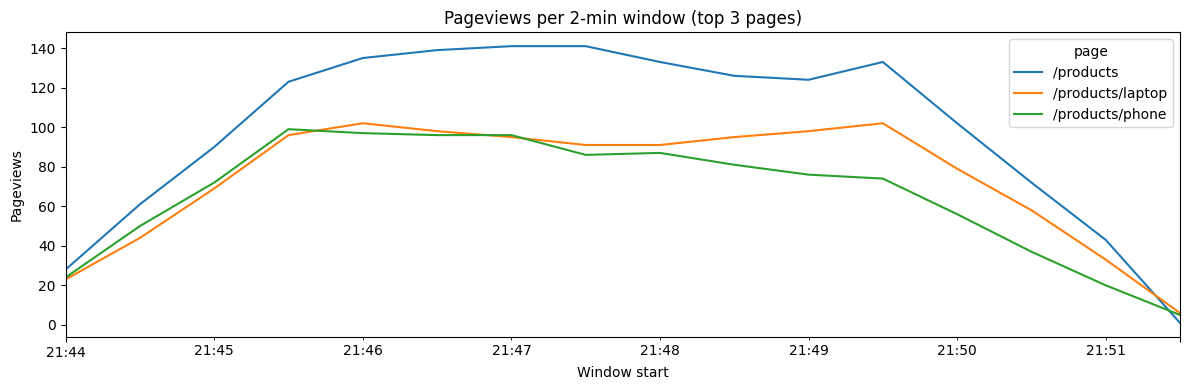

In [34]:
import matplotlib.pyplot as plt, pandas as pd

# Pageviews over time for the top 3 pages
ts = con.execute("""
    WITH top3 AS (
        SELECT page FROM pg.public.clickstream_windows
        GROUP BY page
        ORDER BY SUM(pageviews) DESC
        LIMIT 3
    )
    SELECT w.window_start,
           w.page,
           MAX(w.pageviews) AS pageviews
    FROM pg.public.clickstream_windows w
    INNER JOIN top3 ON top3.page = w.page
    GROUP BY w.window_start, w.page
    ORDER BY w.window_start, w.page
""").df()

if ts.empty:
    print('No data yet — wait a few seconds and re-run')
else:
    pivot = ts.pivot(index='window_start', columns='page', values='pageviews').fillna(0)
    pivot.plot(figsize=(12, 4), title='Pageviews per 2-min window (top 3 pages)')
    plt.xlabel('Window start')
    plt.ylabel('Pageviews')
    plt.tight_layout()
    plt.show()

---
## Step 6 · Simulate a traffic spike

Stop the current producer, start a new one that hammers `/checkout` — you should see the spike appear in the chart within the next window.

In [ ]:
# Stop the old producer
_stop_producer.set()
time.sleep(1)

# Spike: send 200 /checkout events quickly
spike_prod = KafkaProducer(
    bootstrap_servers=KAFKA_SERVERS,
    value_serializer=lambda v: json.dumps(v).encode(),
)
for _ in range(200):
    spike_prod.send('clickstream', value={
        'event_id': str(uuid.uuid4()),
        'user_id':  random.randint(1, N_USERS),
        'page':     '/checkout',
        'referrer': '/cart',
        'ts':       datetime.now(timezone.utc).isoformat(),
    })
spike_prod.flush()
print('Spike sent — re-run the chart cell after the next 15-second trigger')

Producer stopped. Total sent: 1922
Spike sent — re-run the chart cell after the next 15-second trigger


  batch 24: 36 rows → postgres
  batch 25: 28 rows → postgres


---
## Step 7 · Monitor and stop

In [31]:
# Check query health
print('Active?  ', query.isActive)
print('Progress:', query.lastProgress)

Active?   True
Progress: {
    "id": "a1bbdec6-8b6b-4dc7-a017-d2375387dc2e",
    "runId": "bca35164-9408-4e0c-882b-2df5d9e6b37b",
    "name": null,
    "timestamp": "2026-06-17T21:52:45.001Z",
    "batchId": 27,
    "batchDuration": 11,
    "numInputRows": 0,
    "inputRowsPerSecond": 0.0,
    "processedRowsPerSecond": 0.0,
    "durationMs": {
        "latestOffset": 10,
        "triggerExecution": 11
    },
    "eventTime": {
        "watermark": "2026-06-17T21:51:20.339Z"
    },
    "stateOperators": [
        {
            "operatorName": "stateStoreSave",
            "numRowsTotal": 43,
            "numRowsUpdated": 0,
            "allUpdatesTimeMs": 0,
            "numRowsRemoved": 0,
            "allRemovalsTimeMs": 3,
            "commitTimeMs": 2136,
            "memoryUsedBytes": 118624,
            "numRowsDroppedByWatermark": 0,
            "numShufflePartitions": 200,
            "numStateStoreInstances": 200,
            "customMetrics": {
                "loadedMapCacheHi

In [32]:
# Stop everything cleanly
_stop_producer.set()
query.stop()
print('Stream and producer stopped.')

Stream and producer stopped.


26/06/17 21:52:52 WARN DAGScheduler: Failed to cancel job group bca35164-9408-4e0c-882b-2df5d9e6b37b. Cannot find active jobs for it.
26/06/17 21:52:52 WARN DAGScheduler: Failed to cancel job group bca35164-9408-4e0c-882b-2df5d9e6b37b. Cannot find active jobs for it.


---
## Challenge — try it yourself

1. **Tumbling vs sliding windows** — change `window('event_time', '2 minutes', '30 seconds')` to a tumbling window (`window('event_time', '1 minute')`). How does the chart change?

2. **Session windows** — Spark 3.2+ has `session_window(col, gap)`. Replace the time-based window with `session_window('event_time', '30 seconds')` to group events per user session. You'll need to add `user_id` to the `groupBy`.

3. **Upsert instead of append** — `foreachBatch` can run raw SQL. Use `psycopg2` inside `write_batch` to do:
   ```sql
   INSERT INTO clickstream_windows ... ON CONFLICT (window_start, page) DO UPDATE SET ...
   ```
   This keeps exactly one row per (window, page) and makes queries simpler.

4. **Dead-letter queue** — add a second Kafka producer call inside `write_batch` that sends failed rows (e.g. `pageviews > 1000`) to a `clickstream-alerts` topic. Consume that topic in a second `readStream`.

5. **Delta Lake sink** — replace the JDBC `foreachBatch` with a Delta Lake `writeStream` sink (`format('delta')`). Query the Delta table with DuckDB using `delta_scan()` (requires the `duckdb-delta` extension).